In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
movies = pd.read_csv("../data/raw/movies_metadata.csv")
keywords = pd.read_csv("../data/raw/keywords.csv")
credits = pd.read_csv("../data/raw/credits.csv")

print("Movies:", movies.shape)
print("Keywords:", keywords.shape)
print("Credits:", credits.shape)

display(movies.head())

C:\Users\Patrycja\AppData\Local\Temp\ipykernel_19236\520132484.py:1: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  movies = pd.read_csv("../data/raw/movies_metadata.csv")


Movies: (45466, 24)
Keywords: (46419, 2)
Credits: (45476, 3)


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,...,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', ...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his ...",...,1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",NaN,8844,tt0113497,en,Jumanji,When siblings Judy and Peter discover an encha...,...,1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso...",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collect...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",NaN,15602,tt0113228,en,Grumpier Old Men,A family wedding reignites the ancient feud be...,...,1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for...,Grumpier Old Men,False,6.5,92.0
3,False,NaN,16000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",NaN,31357,tt0114885,en,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...",...,1995-12-22,81452156.0,127.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Friends are the people who let you be yourself...,Waiting to Exhale,False,6.1,34.0
4,False,"{'id': 96871, 'name': 'Father of the Bride Col...",0,"[{'id': 35, 'name': 'Comedy'}]",NaN,11862,tt0113041,en,Father of the Bride Part II,Just when George Banks has recovered from his ...,...,1995-02-10,76578911.0,106.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Just When His World Is Back To Normal... He's ...,Father of the Bride Part II,False,5.7,173.0


## Movies

In [36]:
movies.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45466 entries, 0 to 45465
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   adult                  45466 non-null  object 
 1   belongs_to_collection  4494 non-null   object 
 2   budget                 45466 non-null  object 
 3   genres                 45466 non-null  object 
 4   homepage               7782 non-null   object 
 5   id                     45466 non-null  object 
 6   imdb_id                45449 non-null  object 
 7   original_language      45455 non-null  object 
 8   original_title         45466 non-null  object 
 9   overview               44512 non-null  object 
 10  popularity             45461 non-null  object 
 11  poster_path            45080 non-null  object 
 12  production_companies   45463 non-null  object 
 13  production_countries   45463 non-null  object 
 14  release_date           45379 non-null  object 
 15  re

In [37]:
display(movies.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
adult,45466,5,False,45454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
belongs_to_collection,4494,1698,"{'id': 415931, 'name': 'The Bowery Boys', 'pos...",29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
budget,45466,1226,0,36573,NaN,NaN,NaN,NaN,NaN,NaN,NaN
genres,45466,4069,"[{'id': 18, 'name': 'Drama'}]",5000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
homepage,7782,7673,http://www.georgecarlin.com,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
id,45466,45436,141971,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
imdb_id,45449,45417,tt1180333,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_language,45455,92,en,32269,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_title,45466,43373,Alice in Wonderland,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
overview,44512,44307,No overview found.,133,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [38]:
print("Kolumny:")
print(movies.columns.tolist())

Kolumny:
['adult', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id', 'imdb_id', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime', 'spoken_languages', 'status', 'tagline', 'title', 'video', 'vote_average', 'vote_count']


In [39]:
missing = pd.DataFrame({
    "missing_count": movies.isna().sum(),
    "missing_percent": movies.isna().mean() * 100
})

display(missing.sort_values("missing_percent", ascending=False))

,missing_count,missing_percent
belongs_to_collection,40972,90.115691
homepage,37684,82.883913
tagline,25054,55.104914
overview,954,2.098271
poster_path,386,0.848986
runtime,263,0.578454
status,87,0.191352
release_date,87,0.191352
imdb_id,17,0.037391
original_language,11,0.024194


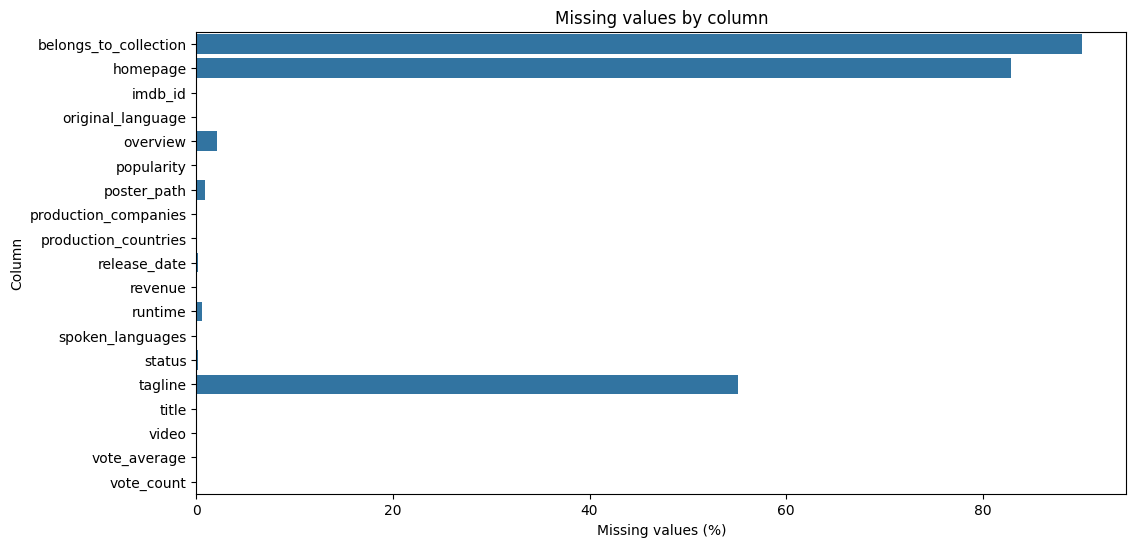

In [40]:
missing_plot = missing[missing["missing_count"] > 0]

plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_plot.reset_index(),
    x="missing_percent",
    y="index"
)

plt.title("Missing values by column")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.show()

In [41]:
print("Duplicated rows:", movies.duplicated().sum())
print("Duplicated movie IDs:", movies["id"].duplicated().sum())
print("Duplicated titles:", movies["title"].duplicated().sum())

Duplicated rows: 13
Duplicated movie IDs: 30
Duplicated titles: 3188


In [42]:
movies["vote_average"] = pd.to_numeric(movies["vote_average"], errors="coerce")
movies["vote_count"] = pd.to_numeric(movies["vote_count"], errors="coerce")

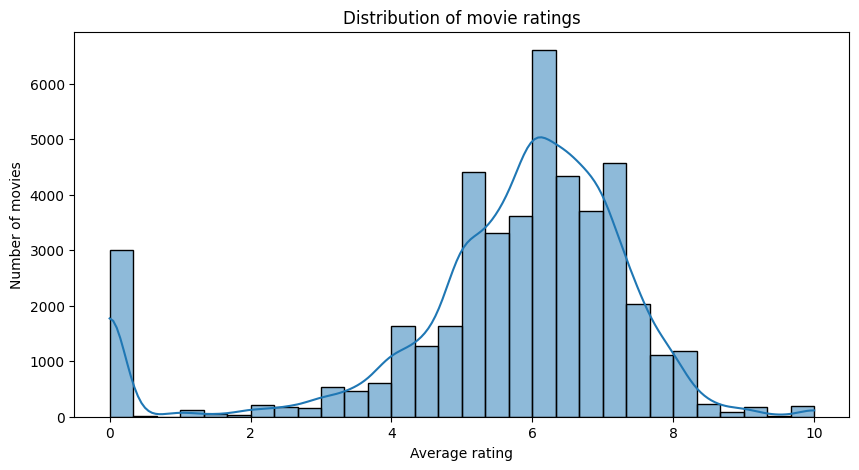

In [43]:
plt.figure(figsize=(10, 5))

sns.histplot(
    movies["vote_average"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of movie ratings")
plt.xlabel("Average rating")
plt.ylabel("Number of movies")
plt.show()

In [44]:
import ast

def extract_genres(value):
    if pd.isna(value):
        return []

    try:
        genres = ast.literal_eval(value)
        return [genre["name"] for genre in genres]
    except (ValueError, SyntaxError, TypeError, KeyError):
        return []

In [45]:
movies["genres_list"] = movies["genres"].apply(extract_genres)

display(movies[["title", "genres_list"]].head())

,title,genres_list
0,Toy Story,"[Animation, Comedy, Family]"
1,Jumanji,"[Adventure, Fantasy, Family]"
2,Grumpier Old Men,"[Romance, Comedy]"
3,Waiting to Exhale,"[Comedy, Drama, Romance]"
4,Father of the Bride Part II,[Comedy]


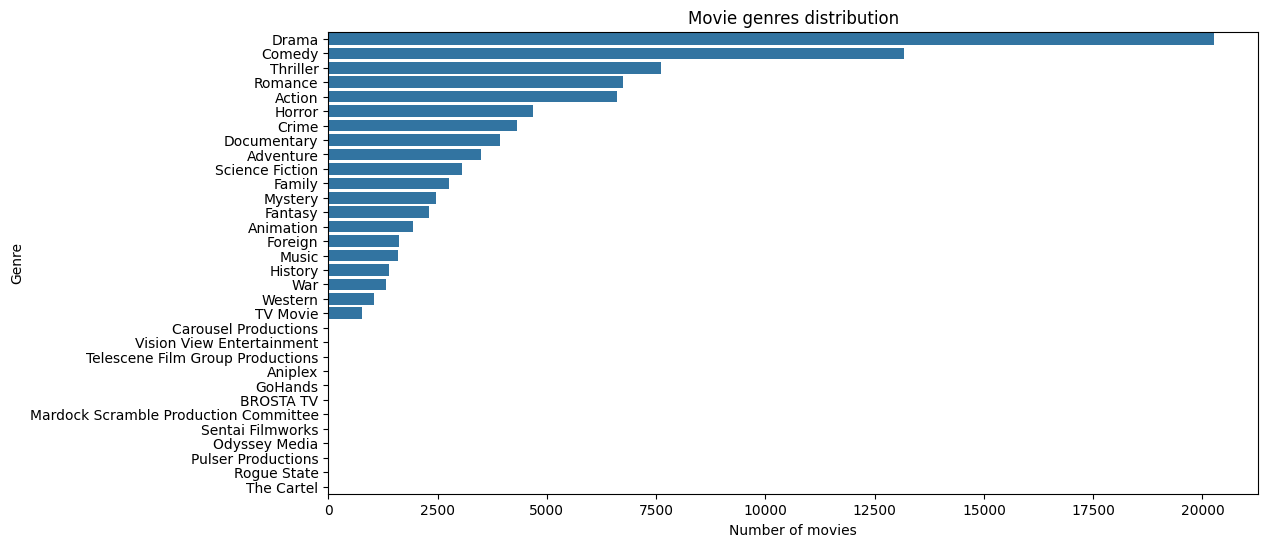

In [46]:
genres_count = (
    movies["genres_list"]
    .explode()
    .dropna()
    .value_counts()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genres_count.values,
    y=genres_count.index
)

plt.title("Movie genres distribution")
plt.xlabel("Number of movies")
plt.ylabel("Genre")
plt.show()

In [47]:
movies["overview_missing"] = (
    movies["overview"].isna() |
    movies["overview"].fillna("").str.strip().eq("")
)

print("Movies without overview:", movies["overview_missing"].sum())
print("Percentage:", round(movies["overview_missing"].mean() * 100, 2),"%")

Movies without overview: 959
Percentage: 2.11 %


In [48]:
movies["runtime"] = pd.to_numeric(movies["runtime"], errors="coerce")
print(movies["runtime"].describe())

count    45203.000000
mean        94.128199
std         38.407810
min          0.000000
25%         85.000000
50%         95.000000
75%        107.000000
max       1256.000000
Name: runtime, dtype: float64


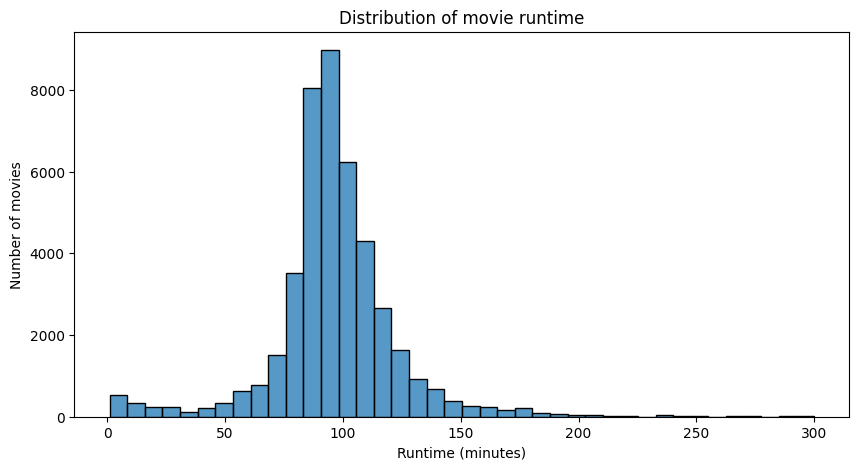

In [49]:
runtime_valid = movies[
    movies["runtime"].between(1, 300)
]

plt.figure(figsize=(10, 5))

sns.histplot(
    runtime_valid["runtime"],
    bins=40
)

plt.title("Distribution of movie runtime")
plt.xlabel("Runtime (minutes)")
plt.ylabel("Number of movies")
plt.show()

## Keywords

In [50]:
print(keywords.shape)
display(keywords.head())

(46419, 2)


,id,keywords
0,862,"[{'id': 931, 'name': 'jealousy'}, {'id': 4290,..."
1,8844,"[{'id': 10090, 'name': 'board game'}, {'id': 1..."
2,15602,"[{'id': 1495, 'name': 'fishing'}, {'id': 12392..."
3,31357,"[{'id': 818, 'name': 'based on novel'}, {'id':..."
4,11862,"[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n..."


In [51]:
def extract_keywords(value):
    if pd.isna(value):
        return []

    try:
        data = ast.literal_eval(value)
        return [item["name"] for item in data]
    except (ValueError, SyntaxError, TypeError, KeyError):
        return []

In [52]:
keywords["keywords_list"] = keywords["keywords"].apply(extract_keywords)
keywords["keywords_count"] = keywords["keywords_list"].apply(len)

display(keywords.head())

,id,keywords,keywords_list,keywords_count
0,862,"[{'id': 931, 'name': 'jealousy'}, {'id': 4290,...","[jealousy, toy, boy, friendship, friends, riva...",9
1,8844,"[{'id': 10090, 'name': 'board game'}, {'id': 1...","[board game, disappearance, based on children'...",6
2,15602,"[{'id': 1495, 'name': 'fishing'}, {'id': 12392...","[fishing, best friend, duringcreditsstinger, o...",4
3,31357,"[{'id': 818, 'name': 'based on novel'}, {'id':...","[based on novel, interracial relationship, sin...",5
4,11862,"[{'id': 1009, 'name': 'baby'}, {'id': 1599, 'n...","[baby, midlife crisis, confidence, aging, daug...",9


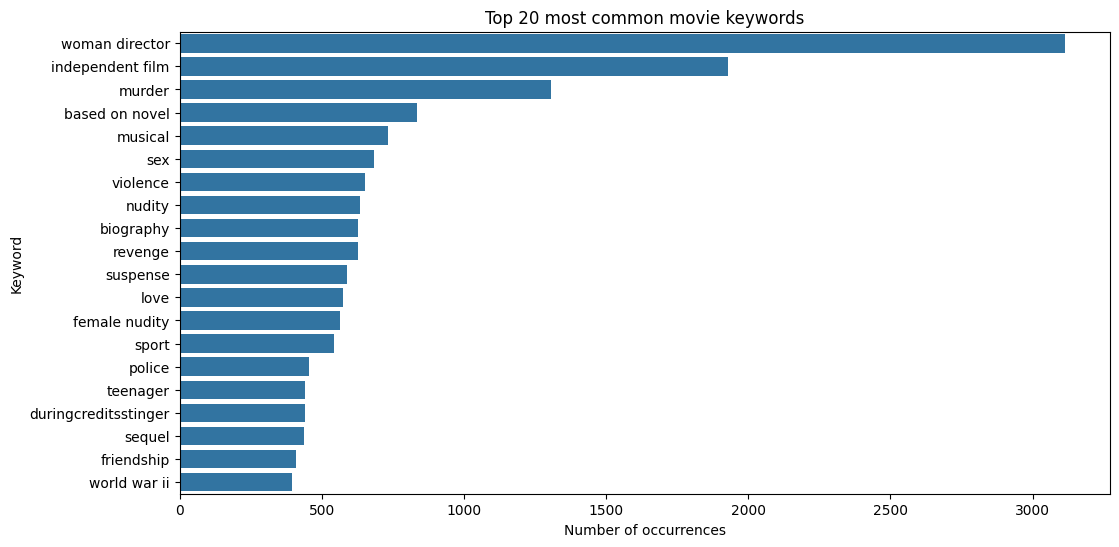

In [53]:
all_keywords = (
    keywords["keywords_list"]
    .explode()
    .dropna()
    .value_counts()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=all_keywords.head(20).values,
    y=all_keywords.head(20).index
)

plt.title("Top 20 most common movie keywords")
plt.xlabel("Number of occurrences")
plt.ylabel("Keyword")
plt.show()

In [54]:
movies["release_date"] = pd.to_datetime(movies["release_date"], errors="coerce")
movies["release_year"] = movies["release_date"].dt.year

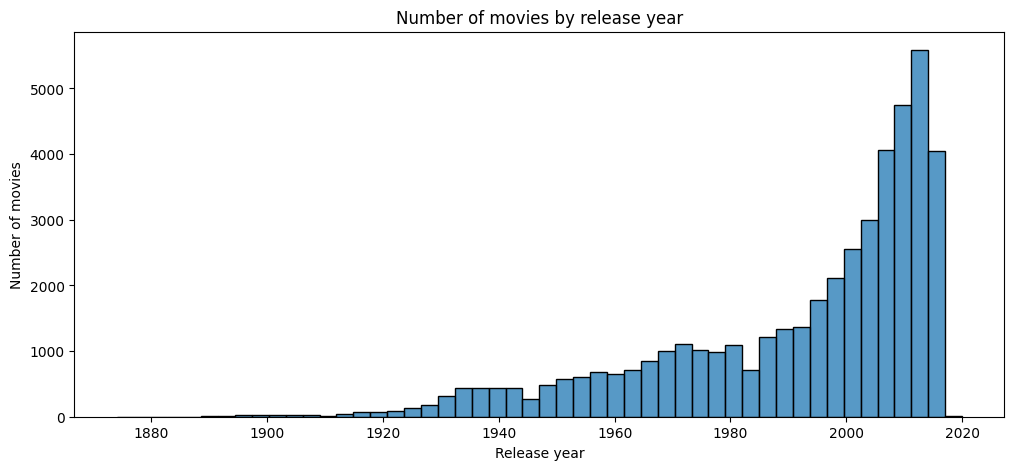

In [55]:
plt.figure(figsize=(12, 5))

sns.histplot(
    movies["release_year"].dropna(),
    bins=50
)

plt.title("Number of movies by release year")
plt.xlabel("Release year")
plt.ylabel("Number of movies")
plt.show()